# Kapitel 1 · Lineare Regression, Basisfunktionen, B-Splines

Begleitnotebook zum Statistik-Wiki. Rechnet die Papieraufgaben nach:

- [[lineare-regression-normalgleichungen]] – Daten aus NB1
- [[basisfunktionen-uebung-folie-30]] – Übung VL1, Folie 30
- [[b-splines-grad-2-von-hand]] – Übung VL1, Folie 41

In der Klausur gibt es **keine Hilfsmittel** – das Notebook dient nur zur Kontrolle und Intuition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction as F
np.set_printoptions(precision=4, suppress=True)

## 1 · Normalgleichung $X^TXa = X^Ty$ (Daten aus NB1)

In [2]:
x = np.array([-7, -4, -2, 0, 2], dtype=float)
y = np.array([1, 2, 2, 0, -1], dtype=float)
X = np.column_stack([np.ones_like(x), x])          # Designmatrix mit Einsen-Spalte
XtX, Xty = X.T @ X, X.T @ y
a = np.linalg.solve(XtX, Xty)
print("X^T X =\n", XtX)
print("X^T y =", Xty)
print("a =", a)
print("Schwerpunkt-Check:", a[0] + a[1] * x.mean(), "==", y.mean())

X^T X =
 [[  5. -11.]
 [-11.  73.]]
X^T y = [  4. -21.]
a = [ 0.25 -0.25]
Schwerpunkt-Check: 0.8 == 0.8


### Ridge: $(X^TX + \lambda I)a = X^Ty$
Ridge verkleinert die **Norm** des Koeffizientenvektors – nicht zwingend jeden Koeffizienten (siehe $a_1$ bei $\lambda=1$).

In [3]:
for lam in [0, 1, 10, 100]:
    a_r = np.linalg.solve(XtX + lam * np.eye(2), Xty)
    print(f"lambda={lam:>4}: a={a_r}, ||a||={np.linalg.norm(a_r):.3f}")

lambda=   0: a=[ 0.25 -0.25], ||a||=0.354
lambda=   1: a=[ 0.2012 -0.2539], ||a||=0.324
lambda=  10: a=[ 0.0899 -0.2411], ||a||=0.257
lambda= 100: a=[ 0.0255 -0.1198], ||a||=0.122


## 2 · Basisfunktionen (Übung VL1, Folie 30)
Basen $\{1,x\}$, $\{1,x,x^2\}$ und Polynom Grad 4 (Interpolation).

Grad 1: a=[ 2.0248 -0.2481], SSE=12.387
Grad 2: a=[ 1.4209 -0.3989  0.1179], SSE=10.199
Grad 4: a=[ 2.     -4.7048 -2.7286  0.1762  0.2   ], SSE=0.000


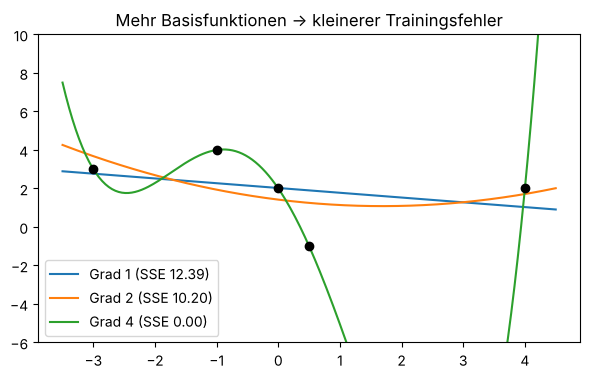

In [4]:
x = np.array([-3, -1, 0, 0.5, 4])
y = np.array([3, 4, 2, -1, 2], dtype=float)

def design(x, degree):
    return np.column_stack([x**k for k in range(degree + 1)])

xg = np.linspace(-3.5, 4.5, 300)
plt.figure(figsize=(7, 4))
for d in [1, 2, 4]:
    B = design(x, d)
    a = np.linalg.solve(B.T @ B, B.T @ y)
    sse = np.sum((y - B @ a) ** 2)
    print(f"Grad {d}: a={a}, SSE={sse:.3f}")
    plt.plot(xg, design(xg, d) @ a, label=f"Grad {d} (SSE {sse:.2f})")
plt.scatter(x, y, c="k", zorder=3)
plt.ylim(-6, 10); plt.legend(); plt.title("Mehr Basisfunktionen → kleinerer Trainingsfehler"); plt.show()

In [5]:
# Exakte Brüche für die Papierlösung mit Basis {1, x}
xs = [F(-3), F(-1), F(0), F(1, 2), F(4)]; ys = [F(3), F(4), F(2), F(-1), F(2)]
n = len(xs); sx = sum(xs); sxx = sum(v * v for v in xs); sy = sum(ys); sxy = sum(u * v for u, v in zip(xs, ys))
det = n * sxx - sx * sx
print("Summen:", sx, sxx, sy, sxy, "Determinante:", det)
print("a0 =", (sxx * sy - sx * sxy) / det, "a1 =", (n * sxy - sx * sy) / det)

Summen: 1/2 105/4 10 -11/2 Determinante: 131
a0 = 1061/524 a1 = -65/262


## 3 · B-Splines mit Cox-de-Boor (Übung VL1, Folie 41)
Knoten $t_1=0, t_2=1, t_3=2, t_4=3$ (hier 0-indiziert). Konvention $0/0 = 0$ für wiederholte Knoten.

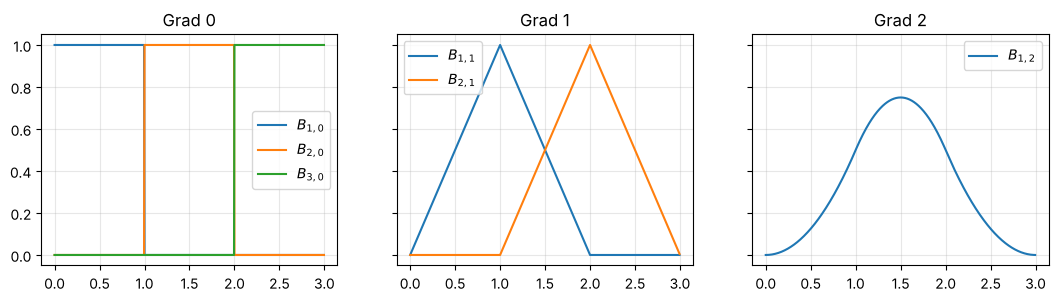

max. Abweichung zur Handlösung: 7.771561172376096e-16
Kontrollwerte: {0.5: 0.125, 1: 0.5, 1.5: 0.75, 2: 0.5, 2.5: 0.125}


In [6]:
def bspline(i, d, x, t):
    if d == 0:
        return np.where((t[i] <= x) & (x < t[i + 1]), 1.0, 0.0)
    left = 0.0 if t[i + d] == t[i] else (x - t[i]) / (t[i + d] - t[i]) * bspline(i, d - 1, x, t)
    right = 0.0 if t[i + d + 1] == t[i + 1] else (t[i + d + 1] - x) / (t[i + d + 1] - t[i + 1]) * bspline(i + 1, d - 1, x, t)
    return left + right

t = [0, 1, 2, 3]
xg = np.linspace(0, 3, 601)[:-1]
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for d, ax in zip([0, 1, 2], axes):
    for i in range(len(t) - d - 1):
        ax.plot(xg, bspline(i, d, xg, t), label=f"$B_{{{i+1},{d}}}$")
    ax.set_title(f"Grad {d}"); ax.legend(); ax.grid(alpha=.3)
plt.show()

closed = np.where(xg < 1, xg**2 / 2, np.where(xg < 2, (-2 * xg**2 + 6 * xg - 3) / 2, (3 - xg)**2 / 2))
print("max. Abweichung zur Handlösung:", np.abs(bspline(0, 2, xg, t) - closed).max())
print("Kontrollwerte:", {v: float(bspline(0, 2, np.array([v]), t)[0]) for v in [0.5, 1, 1.5, 2, 2.5]})

### Zerlegung der Eins nur mit genügend Knoten
Mit nur 4 Knoten gibt es einen einzigen quadratischen B-Spline (Maximum 0,75). Wiederholt man die Randknoten, summieren sich die B-Splines auf dem ganzen Intervall zu 1.

Anzahl Basisfunktionen: 5 | Summe min/max: 0.9999999999999998 1.0000000000000002


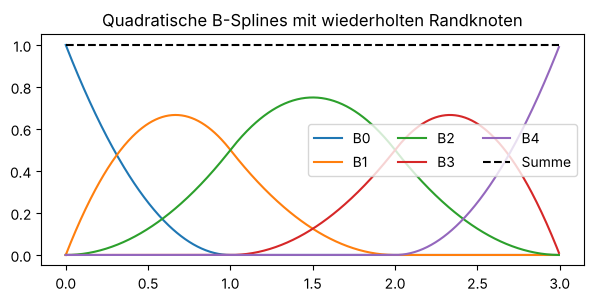

In [7]:
t_ext = [0, 0, 0, 1, 2, 3, 3, 3]           # Randknoten dreifach (Grad 2)
xg = np.linspace(0, 3, 601)[:-1]
basis = [bspline(i, 2, xg, t_ext) for i in range(len(t_ext) - 3)]
print("Anzahl Basisfunktionen:", len(basis), "| Summe min/max:", np.sum(basis, axis=0).min(), np.sum(basis, axis=0).max())
plt.figure(figsize=(7, 3))
for i, b in enumerate(basis):
    plt.plot(xg, b, label=f"B{i}")
plt.plot(xg, np.sum(basis, axis=0), "k--", label="Summe"); plt.legend(ncol=3); plt.title("Quadratische B-Splines mit wiederholten Randknoten"); plt.show()